In [230]:

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from functools import reduce
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [231]:
# 2. DEFINE STUDY PERIOD AND INDICATORS

START_YEAR = None
END_YEAR = None

indicators = {
    "real_gdp": "NY.GDP.MKTP.KD",
    "gdp_growth": "NY.GDP.MKTP.KD.ZG",
    "real_gdp_per_capita": "NY.GDP.PCAP.KD",
    "population": "SP.POP.TOTL",
    "inflation": "FP.CPI.TOTL.ZG",
    "unemployment": "SL.UEM.TOTL.ZS",
    "government_debt_pct_gdp": "GC.DOD.TOTL.GD.ZS",
    "tax_revenue_pct_gdp": "GC.TAX.TOTL.GD.ZS",
    "current_account_pct_gdp": "BN.CAB.XOKA.GD.ZS",
    "exports_pct_gdp": "NE.EXP.GNFS.ZS",
    "imports_pct_gdp": "NE.IMP.GNFS.ZS",
    "fdi_pct_gdp": "BX.KLT.DINV.WD.GD.ZS",
    "gross_capital_formation_pct_gdp": "NE.GDI.TOTL.ZS",
    "domestic_credit_pct_gdp": "FS.AST.PRVT.GD.ZS",
    "agriculture_value_added_pct_gdp": "NV.AGR.TOTL.ZS",
    "industry_value_added_pct_gdp": "NV.IND.TOTL.ZS",
    "manufacturing_value_added_pct_gdp": "NV.IND.MANF.ZS",
    "electricity_access_pct": "EG.ELC.ACCS.ZS",
    "internet_users_pct": "IT.NET.USER.ZS",
    "life_expectancy": "SP.DYN.LE00.IN"
}

print("Total indicators:", len(indicators))
print("GDP per capita:", indicators["real_gdp_per_capita"])

Total indicators: 20
GDP per capita: NY.GDP.PCAP.KD


In [232]:

# 3. FETCH COUNTRY METADATA FROM WORLD BANK

url = "https://api.worldbank.org/v2/country"

response = requests.get(
    url,
    params={
        "format": "json",
        "per_page": 400
    },
    timeout=60
)

response.raise_for_status()
metadata_response = response.json()

if (
    not isinstance(metadata_response, list)
    or len(metadata_response) < 2
    or metadata_response[1] is None
):
    raise ValueError("Failed to retrieve World Bank country metadata.")

country_metadata = pd.DataFrame(metadata_response[1])

# Exclude regional and income-level aggregates
individual_countries = country_metadata[
    country_metadata["region"].apply(
        lambda x: isinstance(x, dict)
        and x.get("id") not in [None, "", "NA"]
    )
].copy()

individual_country_codes = set(
    individual_countries["id"].dropna()
)

country_name_map = dict(
    zip(individual_countries["id"], individual_countries["name"])
)

print("Country/territory metadata retrieved successfully.")
print("Total countries and territories:", len(individual_countries))

display(
    individual_countries[["id", "name", "region"]].head(10)
)


Country/territory metadata retrieved successfully.
Total countries and territories: 217


,id,name,region
0,ABW,Aruba,"{'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}"
2,AFG,Afghanistan,"{'id': 'MEA', 'iso2code': 'ZQ', 'value': 'Middle East, North Africa, Afghanistan & Pakistan'}"
5,AGO,Angola,"{'id': 'SSF', 'iso2code': 'ZG', 'value': 'Sub-Saharan Africa '}"
6,ALB,Albania,"{'id': 'ECS', 'iso2code': 'Z7', 'value': 'Europe & Central Asia'}"
7,AND,Andorra,"{'id': 'ECS', 'iso2code': 'Z7', 'value': 'Europe & Central Asia'}"
9,ARE,United Arab Emirates,"{'id': 'MEA', 'iso2code': 'ZQ', 'value': 'Middle East, North Africa, Afghanistan & Pakistan'}"
10,ARG,Argentina,"{'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}"
11,ARM,Armenia,"{'id': 'ECS', 'iso2code': 'Z7', 'value': 'Europe & Central Asia'}"
12,ASM,American Samoa,"{'id': 'EAS', 'iso2code': 'Z4', 'value': 'East Asia & Pacific'}"
13,ATG,Antigua and Barbuda,"{'id': 'LCN', 'iso2code': 'ZJ', 'value': 'Latin America & Caribbean '}"


In [233]:

# 4. CREATE WORLD BANK DATA RETRIEVAL FUNCTION

def get_indicator(indicator_code, column_name):
    url = (
        "https://api.worldbank.org/v2/country/all/"
        f"indicator/{indicator_code}"
    )

    params = {
        "format": "json",
        "per_page": 20000,
        "page": 1
    }

    all_records = []

    while True:
        response = requests.get(
            url,
            params=params,
            timeout=120
        )
        response.raise_for_status()

        payload = response.json()

        if (
            not isinstance(payload, list)
            or len(payload) < 2
            or payload[1] is None
        ):
            break

        metadata, records = payload

        for record in records:
            country_info = record.get("country", {})
            country_code = record.get("countryiso3code")
            year = record.get("date")
            value = record.get("value")

            # Keep only individual countries/territories
            if country_code not in individual_country_codes:
                continue

            all_records.append({
                "country_code": country_code,
                "country": country_name_map.get(
                    country_code,
                    country_info.get("value")
                ),
                "year": year,
                column_name: value
            })

        total_pages = metadata.get("pages", 1)

        if params["page"] >= total_pages:
            break

        params["page"] += 1

    df = pd.DataFrame(
        all_records,
        columns=[
            "country_code",
            "country",
            "year",
            column_name
        ]
    )

    if not df.empty:
        df["year"] = pd.to_numeric(
            df["year"], errors="coerce"
        ).astype("Int64")

        df[column_name] = pd.to_numeric(
            df[column_name], errors="coerce"
        )

        df = df.dropna(subset=["year"])

    return df


print("World Bank retrieval function is ready.")


World Bank retrieval function is ready.


In [234]:

# 5. TEST DATA RETRIEVAL: GDP GROWTH

test_df = get_indicator(
    indicator_code="NY.GDP.MKTP.KD.ZG",
    column_name="gdp_growth"
)

print("Dataset shape:", test_df.shape)
print("Year range:", test_df["year"].min(), "-", test_df["year"].max())
print("Countries/territories:", test_df["country_code"].nunique())
print("Missing values:", test_df["gdp_growth"].isna().sum())

display(test_df.head(10))
display(test_df.tail(10))


Dataset shape: (14322, 4)
Year range: 1960 - 2025
Countries/territories: 217
Missing values: 2914


,country_code,country,year,gdp_growth
0,AFG,Afghanistan,2025,NaN
1,AFG,Afghanistan,2024,1.87
2,AFG,Afghanistan,2023,2.27
3,AFG,Afghanistan,2022,-6.24
4,AFG,Afghanistan,2021,-20.74
5,AFG,Afghanistan,2020,-2.35
6,AFG,Afghanistan,2019,3.91
7,AFG,Afghanistan,2018,1.19
8,AFG,Afghanistan,2017,2.65
9,AFG,Afghanistan,2016,2.26


,country_code,country,year,gdp_growth
14312,ZWE,Zimbabwe,1969,12.43
14313,ZWE,Zimbabwe,1968,1.97
14314,ZWE,Zimbabwe,1967,8.37
14315,ZWE,Zimbabwe,1966,1.52
14316,ZWE,Zimbabwe,1965,4.91
14317,ZWE,Zimbabwe,1964,-1.11
14318,ZWE,Zimbabwe,1963,6.24
14319,ZWE,Zimbabwe,1962,1.43
14320,ZWE,Zimbabwe,1961,6.32
14321,ZWE,Zimbabwe,1960,NaN


In [235]:
# 6. FETCH ALL 20 ECONOMIC INDICATORS

indicator_data = {}
failed_indicators = {}

for name, code in indicators.items():
    print(f"Fetching {name} ({code})...")

    try:
        df = get_indicator(
            indicator_code=code,
            column_name=name
        )

        if df.empty:
            failed_indicators[name] = "No data returned"
            print("  WARNING: No data returned.")
            continue

        indicator_data[name] = df
        print(f"  Retrieved: {len(df):,} rows")

    except Exception as e:
        failed_indicators[name] = str(e)
        print(f"  ERROR fetching {name}: {e}")

print("\n=== DATA RETRIEVAL SUMMARY ===")
print("Expected indicators:", len(indicators))
print("Successfully retrieved:", len(indicator_data))
print("Failed indicators:", len(failed_indicators))

if failed_indicators:
    print("\n=== FAILED INDICATORS ===")

    for name, error in failed_indicators.items():
        print(f"- {name}: {error}")

    raise RuntimeError(
        "Data retrieval incomplete. "
        "Please retry the failed indicators before proceeding."
    )

if len(indicator_data) != 20:
    raise ValueError(
        f"Expected 20 indicators, "
        f"but retrieved {len(indicator_data)}."
    )

print("\nSUCCESS: All 20 indicators retrieved successfully.")

Fetching real_gdp (NY.GDP.MKTP.KD)...
  Retrieved: 14,322 rows
Fetching gdp_growth (NY.GDP.MKTP.KD.ZG)...
  Retrieved: 14,322 rows
Fetching real_gdp_per_capita (NY.GDP.PCAP.KD)...
  Retrieved: 14,322 rows
Fetching population (SP.POP.TOTL)...
  Retrieved: 14,322 rows
Fetching inflation (FP.CPI.TOTL.ZG)...
  Retrieved: 14,322 rows
Fetching unemployment (SL.UEM.TOTL.ZS)...
  Retrieved: 14,322 rows
Fetching government_debt_pct_gdp (GC.DOD.TOTL.GD.ZS)...
  Retrieved: 14,322 rows
Fetching tax_revenue_pct_gdp (GC.TAX.TOTL.GD.ZS)...
  Retrieved: 14,322 rows
Fetching current_account_pct_gdp (BN.CAB.XOKA.GD.ZS)...
  Retrieved: 14,322 rows
Fetching exports_pct_gdp (NE.EXP.GNFS.ZS)...
  Retrieved: 14,322 rows
Fetching imports_pct_gdp (NE.IMP.GNFS.ZS)...
  Retrieved: 14,322 rows
Fetching fdi_pct_gdp (BX.KLT.DINV.WD.GD.ZS)...
  Retrieved: 14,322 rows
Fetching gross_capital_formation_pct_gdp (NE.GDI.TOTL.ZS)...
  Retrieved: 14,322 rows
Fetching domestic_credit_pct_gdp (FS.AST.PRVT.GD.ZS)...
  Retriev

In [236]:

# 6.1 FETCH INDICATOR DEFINITIONS AND METADATA

metadata_records = []
failed_metadata = {}

# Standardized units for documentation
unit_mapping = {
    "real_gdp": "Constant 2015 US$",
    "gdp_growth": "Percent per year",
    "real_gdp_per_capita": "Constant 2015 US$ per capita",
    "population": "Persons",
    "inflation": "Percent per year",
    "unemployment": "Percent of labor force",
    "government_debt_pct_gdp": "Percent of GDP",
    "tax_revenue_pct_gdp": "Percent of GDP",
    "current_account_pct_gdp": "Percent of GDP",
    "exports_pct_gdp": "Percent of GDP",
    "imports_pct_gdp": "Percent of GDP",
    "fdi_pct_gdp": "Percent of GDP",
    "gross_capital_formation_pct_gdp": "Percent of GDP",
    "domestic_credit_pct_gdp": "Percent of GDP",
    "agriculture_value_added_pct_gdp": "Percent of GDP",
    "industry_value_added_pct_gdp": "Percent of GDP",
    "manufacturing_value_added_pct_gdp": "Percent of GDP",
    "electricity_access_pct": "Percent of population",
    "internet_users_pct": "Percent of population",
    "life_expectancy": "Years"
}

for variable_name, indicator_code in indicators.items():
    print(
        f"Fetching metadata: {variable_name} "
        f"({indicator_code})..."
    )

    url = (
        "https://api.worldbank.org/v2/indicator/"
        f"{indicator_code}?format=json"
    )

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        result = response.json()

        if len(result) < 2 or not result[1]:
            failed_metadata[indicator_code] = (
                "Metadata not found"
            )
            print("  WARNING: Metadata not found.")
            continue

        item = result[1][0]

        metadata_records.append({
            "variable_name": variable_name,
            "indicator_code": indicator_code,
            "official_name": item.get("name"),
            "unit": item.get("unit"),
            "unit_clean": unit_mapping.get(
                variable_name, "Check official metadata"
            ),
            "definition": item.get("sourceNote"),
            "source_organization": item.get(
                "sourceOrganization"
            ),
            "source_database": item.get(
                "source", {}
            ).get("value")
        })

        print("  Metadata retrieved successfully.")

    except (
        requests.RequestException,
        ValueError,
        TypeError
    ) as e:
        failed_metadata[indicator_code] = str(e)
        print(f"  ERROR: {e}")

# Create metadata DataFrame
indicator_metadata = pd.DataFrame(metadata_records)

# Display indicator definitions
print("\n=== WORLD BANK INDICATOR DEFINITIONS ===")

if not indicator_metadata.empty:
    display(
        indicator_metadata[
            [
                "variable_name",
                "indicator_code",
                "official_name",
                "unit",
                "unit_clean",
                "definition",
                "source_organization",
                "source_database"
            ]
        ]
    )

# Retrieval summary
print("\n=== METADATA RETRIEVAL SUMMARY ===")
print("Expected indicators:", len(indicators))
print("Successfully retrieved:", len(indicator_metadata))
print("Failed metadata:", len(failed_metadata))

if failed_metadata:
    print("\n=== FAILED METADATA ===")

    for code, error in failed_metadata.items():
        print(f"- {code}: {error}")


Fetching metadata: real_gdp (NY.GDP.MKTP.KD)...
  Metadata retrieved successfully.
Fetching metadata: gdp_growth (NY.GDP.MKTP.KD.ZG)...
  Metadata retrieved successfully.
Fetching metadata: real_gdp_per_capita (NY.GDP.PCAP.KD)...
  Metadata retrieved successfully.
Fetching metadata: population (SP.POP.TOTL)...
  Metadata retrieved successfully.
Fetching metadata: inflation (FP.CPI.TOTL.ZG)...
  Metadata retrieved successfully.
Fetching metadata: unemployment (SL.UEM.TOTL.ZS)...
  Metadata retrieved successfully.
Fetching metadata: government_debt_pct_gdp (GC.DOD.TOTL.GD.ZS)...
  Metadata retrieved successfully.
Fetching metadata: tax_revenue_pct_gdp (GC.TAX.TOTL.GD.ZS)...
  Metadata retrieved successfully.
Fetching metadata: current_account_pct_gdp (BN.CAB.XOKA.GD.ZS)...
  Metadata retrieved successfully.
Fetching metadata: exports_pct_gdp (NE.EXP.GNFS.ZS)...
  Metadata retrieved successfully.
Fetching metadata: imports_pct_gdp (NE.IMP.GNFS.ZS)...
  Metadata retrieved successfully.
Fet

,variable_name,indicator_code,official_name,unit,unit_clean,definition,source_organization,source_database
0,real_gdp,NY.GDP.MKTP.KD,GDP (constant 2015 US$),,Constant 2015 US$,"Gross domestic product is the total income earned through the production of goods and services in an economic territory during an accounting period. It can be measured in three different ways: using either the expenditure approach, the income approach, or the production approach. This indicator is expressed in constant prices, meaning the series has been adjusted to account for price changes over time. The reference year for this adjustment is 2015. This indicator is expressed in United States dollars.","Country official statistics, National Statistical Organizations and/or Central Banks;\nNational Accounts data files, Organisation for Economic Co-operation and Development (OECD);\nStaff estimates, World Bank (WB)",World Development Indicators
1,gdp_growth,NY.GDP.MKTP.KD.ZG,GDP growth (annual %),,Percent per year,"Gross domestic product is the total income earned through the production of goods and services in an economic territory during an accounting period. It can be measured in three different ways: using either the expenditure approach, the income approach, or the production approach. This indicator denotes the percentage change over each previous year of the constant price (base year 2015) series in United States dollars.","Country official statistics, National Statistical Organizations and/or Central Banks;\nNational Accounts data files, Organisation for Economic Co-operation and Development (OECD);\nStaff estimates, World Bank (WB)",World Development Indicators
2,real_gdp_per_capita,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),,Constant 2015 US$ per capita,"Gross domestic product is the total income earned through the production of goods and services in an economic territory during an accounting period. It can be measured in three different ways: using either the expenditure approach, the income approach, or the production approach. The core indicator has been divided by the general population to achieve a per capita estimate.This indicator is expressed in constant prices, meaning the series has been adjusted to account for price changes over time. The reference year for this adjustment is 2015. This indicator is expressed in United States dollars.","Country official statistics, National Statistical Organizations and/or Central Banks;\nNational Accounts data files, Organisation for Economic Co-operation and Development (OECD);\nStaff estimates, World Bank (WB)",World Development Indicators
3,population,SP.POP.TOTL,"Population, total",,Persons,"Total population is based on the de facto definition of population, which counts all residents regardless of legal status or citizenship. The values shown are midyear estimates.","World Population Prospects, United Nations (UN), uri: https://population.un.org/wpp/, publisher: UN Population Division;\nStatistical databases and publications from national statistical offices, National Statistical Offices (NSOs), uri: https://unstats.un.org/home/nso_sites/, publisher: National Statistical Offices;\nEurostat: Demographic Statistics, Eurostat (ESTAT), uri: https://ec.europa.eu/eurostat/data/database?node_code=earn_ses_monthly, publisher: Eurostat;\nPopulation and Vital Statistics Report (various years), United Nations (UN), uri: https://unstats.un.org, publisher: UN Statistics Division",World Development Indicators
4,inflation,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",,Percent per year,"Inflation as measured by the consumer price index reflects the annual percentage change in the cost to the average consumer of acquiring a basket of goods and services that may be fixed or changed at specified intervals, such as yearly.","International Financial Statistics database, International Monetary Fund (IMF)",World Development Indicators
5,unemployment,SL.UEM.TOTL.ZS,"Unemployment, total (% of total labo


=== METADATA RETRIEVAL SUMMARY ===
Expected indicators: 20
Successfully retrieved: 20
Failed metadata: 0


In [237]:

# 7. MERGE ALL INDICATORS INTO ONE DATASET

merge_keys = ["country_code", "year"]
dataframes_to_merge = []

# Ensure all indicators were retrieved
if len(indicator_data) != len(indicators):
    raise ValueError(
        "Data retrieval incomplete. "
        "Please check Section 6 before merging."
    )

for name in indicators:
    df = indicator_data[name]

    # Validate required columns
    required_columns = merge_keys + [name]
    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing columns in {name}: {missing_columns}"
        )

    # Check duplicate country-year combinations
    if df.duplicated(subset=merge_keys).any():
        raise ValueError(
            f"Duplicate country-year rows found in {name}."
        )

    # Keep only merge keys and the indicator column
    temp_df = df[merge_keys + [name]].copy()
    dataframes_to_merge.append(temp_df)

# Merge all indicators using country code and year
economic_data = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=merge_keys,
        how="outer",
        validate="one_to_one"
    ),
    dataframes_to_merge
)

# Add country names after merging
economic_data["country"] = economic_data[
    "country_code"
].map(country_name_map)

# Arrange columns
economic_data = economic_data[
    ["country_code", "country", "year", *indicators.keys()]
]

# Sort dataset
economic_data = economic_data.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

# Display merge results
print("=== MERGE SUMMARY ===")
print("Dataset shape:", economic_data.shape)
print(
    "Total indicators:",
    len(indicators)
)
print(
    "Unique countries/territories:",
    economic_data["country_code"].nunique()
)
print(
    "Year range:",
    economic_data["year"].min(),
    "-",
    economic_data["year"].max()
)
print(
    "Duplicate country-year rows:",
    economic_data.duplicated(
        subset=merge_keys
    ).sum()
)

print("\n=== DATASET PREVIEW ===")
display(economic_data.head())


=== MERGE SUMMARY ===
Dataset shape: (14322, 23)
Total indicators: 20
Unique countries/territories: 217
Year range: 1960 - 2025
Duplicate country-year rows: 0

=== DATASET PREVIEW ===


,country_code,country,year,real_gdp,gdp_growth,real_gdp_per_capita,population,inflation,unemployment,government_debt_pct_gdp,tax_revenue_pct_gdp,current_account_pct_gdp,exports_pct_gdp,imports_pct_gdp,fdi_pct_gdp,gross_capital_formation_pct_gdp,domestic_credit_pct_gdp,agriculture_value_added_pct_gdp,industry_value_added_pct_gdp,manufacturing_value_added_pct_gdp,electricity_access_pct,internet_users_pct,life_expectancy
0,ABW,Aruba,1960,NaN,NaN,NaN,"54,922.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.05
1,ABW,Aruba,1961,NaN,NaN,NaN,"55,578.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.22
2,ABW,Aruba,1962,NaN,NaN,NaN,"56,320.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.60
3,ABW,Aruba,1963,NaN,NaN,NaN,"57,002.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.94
4,ABW,Aruba,1964,NaN,NaN,NaN,"57,619.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.30


In [238]:

# 8. INITIAL DATA QUALITY CHECK

indicator_columns = list(indicators.keys())

# 1. Dataset overview
print("=== DATASET OVERVIEW ===")
print(f"Total rows: {len(economic_data):,}")
print(f"Total columns: {len(economic_data.columns)}")
print(
    "Unique countries/territories:",
    economic_data["country_code"].nunique()
)
print(
    f"Year range: {economic_data['year'].min()} "
    f"- {economic_data['year'].max()}"
)
print("Total indicators:", len(indicator_columns))

# 2. Check duplicate country-year combinations
duplicate_count = economic_data.duplicated(
    subset=["country_code", "year"]
).sum()

print("\n=== DUPLICATE CHECK ===")
print(f"Duplicate country-year rows: {duplicate_count:,}")

# 3. Missing values per indicator
missing_summary = pd.DataFrame({
    "missing_count": economic_data[indicator_columns].isna().sum(),
    "missing_percentage": (
        economic_data[indicator_columns].isna().mean() * 100
    ).round(2)
})

print("\n=== MISSING VALUES BY INDICATOR ===")
display(
    missing_summary.sort_values(
        "missing_percentage",
        ascending=False
    )
)

# 4. Check essential identifiers
identifier_summary = pd.DataFrame({
    "missing_count": economic_data[
        ["country_code", "country", "year"]
    ].isna().sum()
})

print("\n=== IDENTIFIER CHECK ===")
display(identifier_summary)

# 5. Data types and memory usage
print("\n=== DATASET INFORMATION ===")
economic_data.info()


=== DATASET OVERVIEW ===
Total rows: 14,322
Total columns: 23
Unique countries/territories: 217
Year range: 1960 - 2025
Total indicators: 20

=== DUPLICATE CHECK ===
Duplicate country-year rows: 0

=== MISSING VALUES BY INDICATOR ===


,missing_count,missing_percentage
government_debt_pct_gdp,12673,88.49
tax_revenue_pct_gdp,9614,67.13
internet_users_pct,8098,56.54
unemployment,7791,54.40
electricity_access_pct,7575,52.89
domestic_credit_pct_gdp,6648,46.42
current_account_pct_gdp,6549,45.73
manufacturing_value_added_pct_gdp,6069,42.38
gross_capital_formation_pct_gdp,5652,39.46
exports_pct_gdp,5293,36.96



=== IDENTIFIER CHECK ===


,missing_count
country_code,0
country,0
year,0



=== DATASET INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14322 entries, 0 to 14321
Data columns (total 23 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country_code                       14322 non-null  object 
 1   country                            14322 non-null  object 
 2   year                               14322 non-null  Int64  
 3   real_gdp                           11533 non-null  float64
 4   gdp_growth                         11408 non-null  float64
 5   real_gdp_per_capita                11533 non-null  float64
 6   population                         14292 non-null  float64
 7   inflation                          9151 non-null   float64
 8   unemployment                       6531 non-null   float64
 9   government_debt_pct_gdp            1649 non-null   float64
 10  tax_revenue_pct_gdp                4708 non-null   float64
 11  current_account_pct_gdp  

In [239]:

# 9.1 DATA COVERAGE ANALYSIS

coverage_records = []

total_rows = len(economic_data)

for col in indicator_columns:
    valid_data = economic_data.loc[
        economic_data[col].notna(),
        ["year", col]
    ]

    coverage_records.append({
        "indicator": col,
        "available_observations": len(valid_data),
        "missing_observations": total_rows - len(valid_data),
        "coverage_pct": (
            valid_data.shape[0] / total_rows * 100
            if total_rows > 0 else np.nan
        ),
        "earliest_year": (
            int(valid_data["year"].min())
            if not valid_data.empty else None
        ),
        "latest_year": (
            int(valid_data["year"].max())
            if not valid_data.empty else None
        )
    })

coverage_summary = pd.DataFrame(coverage_records)

coverage_summary["coverage_pct"] = (
    coverage_summary["coverage_pct"].round(2)
)

coverage_summary = coverage_summary.sort_values(
    "coverage_pct",
    ascending=True
).reset_index(drop=True)

print("=== DATA COVERAGE SUMMARY ===")
print("Total dataset rows:", f"{total_rows:,}")
print("Total indicators:", len(indicator_columns))

display(coverage_summary)


=== DATA COVERAGE SUMMARY ===
Total dataset rows: 14,322
Total indicators: 20


,indicator,available_observations,missing_observations,coverage_pct,earliest_year,latest_year
0,government_debt_pct_gdp,1649,12673,11.51,1970,2024
1,tax_revenue_pct_gdp,4708,9614,32.87,1972,2024
2,internet_users_pct,6224,8098,43.46,1990,2025
3,unemployment,6531,7791,45.60,1991,2025
4,electricity_access_pct,6747,7575,47.11,1990,2024
5,domestic_credit_pct_gdp,7674,6648,53.58,1960,2025
6,current_account_pct_gdp,7773,6549,54.27,1960,2025
7,manufacturing_value_added_pct_gdp,8253,6069,57.62,1960,2025
8,gross_capital_formation_pct_gdp,8670,5652,60.54,1960,2025
9,exports_pct_gdp,9029,5293,63.04,1960,2025


In [240]:

# 9.2 DATA CLEANING AND STANDARDIZATION

clean_data = economic_data.copy()

# 1. Standardize country codes and names
for col in ["country_code", "country"]:
    clean_data[col] = (
        clean_data[col]
        .astype("string")
        .str.strip()
    )

# Convert empty strings to missing values
clean_data[["country_code", "country"]] = (
    clean_data[["country_code", "country"]]
    .replace("", pd.NA)
)

# 2. Standardize year
clean_data["year"] = pd.to_numeric(
    clean_data["year"],
    errors="coerce"
).astype("Int64")

# 3. Convert indicator columns to numeric
for col in indicator_columns:
    clean_data[col] = pd.to_numeric(
        clean_data[col],
        errors="coerce"
    )

# 4. Check missing essential identifiers
missing_identifiers = clean_data[
    ["country_code", "country", "year"]
].isna().sum()

print("=== MISSING IDENTIFIERS ===")
display(missing_identifiers.to_frame("missing_count"))

# Remove rows with missing essential identifiers
rows_before = len(clean_data)

clean_data = clean_data.dropna(
    subset=["country_code", "country", "year"]
).copy()

rows_removed = rows_before - len(clean_data)

print("Rows removed due to missing identifiers:", rows_removed)

# 5. Check duplicate country-year combinations
duplicate_count = clean_data.duplicated(
    subset=["country_code", "year"]
).sum()

print("Duplicate country-year rows:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate country-year records detected. "
        "Investigate duplicates before proceeding."
    )

# 6. Sort the dataset
clean_data = clean_data.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("\n=== CLEANING SUMMARY ===")
print("Dataset shape:", clean_data.shape)
print("Unique countries:", clean_data["country_code"].nunique())
print("Year range:", clean_data["year"].min(), "-", clean_data["year"].max())
print(
    "Missing indicator values:",
    clean_data[indicator_columns].isna().sum().sum()
)

print("\nData cleaning completed.")


=== MISSING IDENTIFIERS ===


,missing_count
country_code,0
country,0
year,0


Rows removed due to missing identifiers: 0
Duplicate country-year rows: 0

=== CLEANING SUMMARY ===
Dataset shape: (14322, 23)
Unique countries: 217
Year range: 1960 - 2025
Missing indicator values: 110586

Data cleaning completed.


In [241]:

# 9.3 CHECK POTENTIAL INVALID VALUES

# Define indicators with expected value ranges
value_rules = {
    # Indicators that should be non-negative
    "real_gdp": (0, None),
    "real_gdp_per_capita": (0, None),
    "population": (0, None),
    "life_expectancy": (0, 120),

    # Indicators bounded between 0 and 100
    "unemployment": (0, 100),
    "electricity_access_pct": (0, 100),
    "internet_users_pct": (0, 100)
}

invalid_records = []

# Check each indicator against its expected range
for col, (lower_bound, upper_bound) in value_rules.items():

    # Verify that the column exists
    if col not in clean_data.columns:
        print(f"WARNING: Column '{col}' not found. Skipping.")
        continue

    # Identify available values
    available = clean_data[col].notna()

    # Initialize invalid-value mask
    invalid_mask = pd.Series(
        False,
        index=clean_data.index
    )

    # Check lower bound
    if lower_bound is not None:
        invalid_mask |= clean_data[col] < lower_bound

    # Check upper bound
    if upper_bound is not None:
        invalid_mask |= clean_data[col] > upper_bound

    # Extract potential invalid records
    invalid_rows = clean_data.loc[
        available & invalid_mask,
        ["country_code", "country", "year", col]
    ].copy()

    # Store flagged records
    if not invalid_rows.empty:
        invalid_rows["indicator"] = col
        invalid_rows["issue"] = "Outside expected range"

        invalid_records.append(invalid_rows)

# Combine all potential invalid records
if invalid_records:

    potential_invalid_values = pd.concat(
        invalid_records,
        ignore_index=True
    )

    # Arrange output columns
    potential_invalid_values = potential_invalid_values[
        [
            "country_code",
            "country",
            "year",
            "indicator",
            "issue",
            *[
                col for col in value_rules
                if col in potential_invalid_values.columns
            ]
        ]
    ]

    print(
        "Potential invalid records:",
        len(potential_invalid_values)
    )

    display(potential_invalid_values.head(30))

else:
    potential_invalid_values = pd.DataFrame()

    print("No potential invalid values detected.")

# Final note
print(
    "\nNote: Flagged records must be checked against "
    "the original source before correction or removal."
)


No potential invalid values detected.

Note: Flagged records must be checked against the original source before correction or removal.


In [242]:

# 9.4 MISSING VALUES BY YEAR

# Calculate missing values for each indicator by year
missing_by_year = (
    clean_data.groupby("year")[indicator_columns]
    .agg(lambda col: col.isna().sum())
)

# Total missing indicator values per year
missing_by_year["total_missing"] = (
    missing_by_year[indicator_columns].sum(axis=1)
)

# Total possible indicator values per year
rows_per_year = clean_data.groupby("year").size()

missing_by_year["total_cells"] = (
    rows_per_year * len(indicator_columns)
)

# Calculate missing percentage
missing_by_year["missing_pct"] = (
    missing_by_year["total_missing"]
    / missing_by_year["total_cells"]
    * 100
).round(2)

# Display years with the highest missing-data percentage
print("=== YEARS WITH HIGHEST MISSING-DATA PERCENTAGE ===")

display(
    missing_by_year[
        ["total_missing", "total_cells", "missing_pct"]
    ]
    .sort_values("missing_pct", ascending=False)
    .head(15)
)

# Display the most recent years
print("\n=== MOST RECENT YEARS ===")

display(
    missing_by_year[
        ["total_missing", "total_cells", "missing_pct"]
    ]
    .sort_index(ascending=False)
    .head(10)
)


=== YEARS WITH HIGHEST MISSING-DATA PERCENTAGE ===


,total_missing,total_cells,missing_pct
year,,,
1960,3305,4340,76.15
1961,3172,4340,73.09
1962,3151,4340,72.60
1963,3135,4340,72.24
1964,3121,4340,71.91
1965,3049,4340,70.25
1966,3016,4340,69.49
1967,2993,4340,68.96
1968,2976,4340,68.57



=== MOST RECENT YEARS ===


,total_missing,total_cells,missing_pct
year,,,
2025,1929,4340,44.45
2024,849,4340,19.56
2023,751,4340,17.30
2022,696,4340,16.04
2021,672,4340,15.48
2020,644,4340,14.84
2019,623,4340,14.35
2018,624,4340,14.38
2017,597,4340,13.76


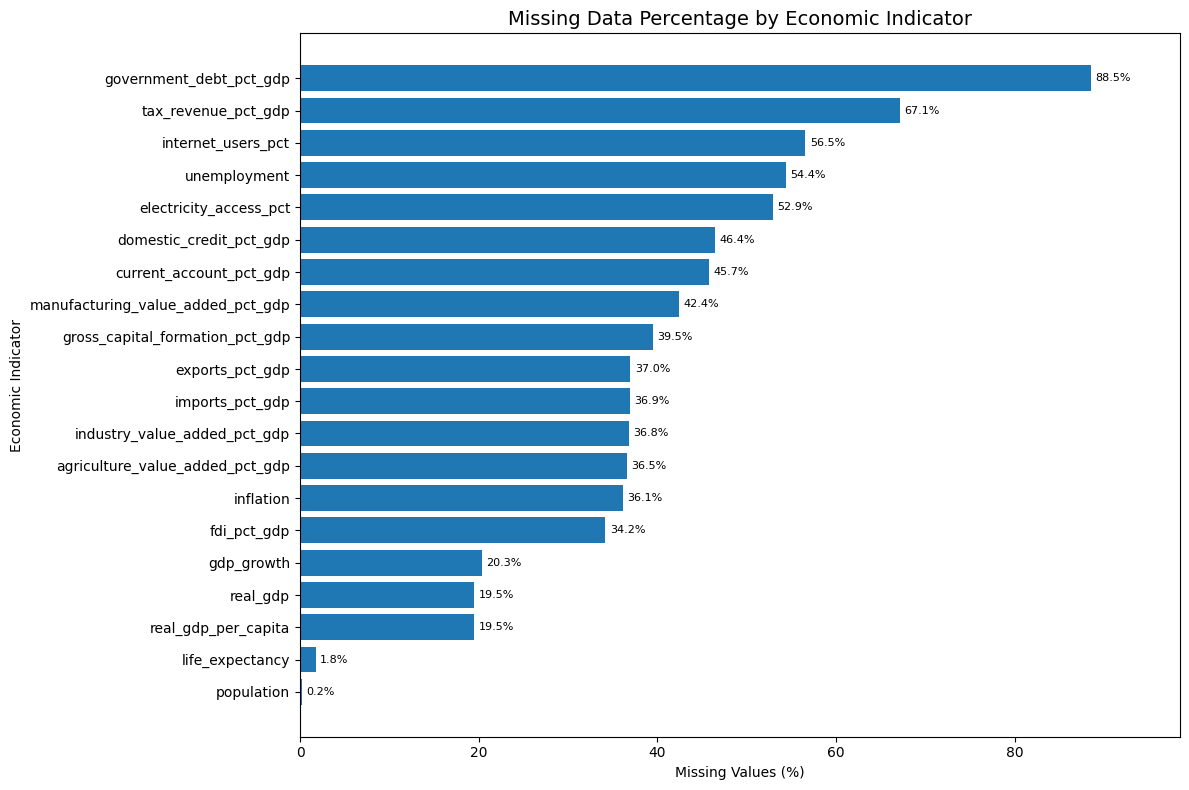

=== MISSING DATA SUMMARY ===


,missing_count,missing_percentage
government_debt_pct_gdp,12673,88.49
tax_revenue_pct_gdp,9614,67.13
internet_users_pct,8098,56.54
unemployment,7791,54.40
electricity_access_pct,7575,52.89
domestic_credit_pct_gdp,6648,46.42
current_account_pct_gdp,6549,45.73
manufacturing_value_added_pct_gdp,6069,42.38
gross_capital_formation_pct_gdp,5652,39.46
exports_pct_gdp,5293,36.96


In [243]:

# 9.5 VISUALIZE MISSING DATA PATTERNS

# Calculate missing percentage for each indicator
missing_pct = (
    clean_data[indicator_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=True)
)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

bars = plt.barh(
    missing_pct.index,
    missing_pct.values
)

plt.title(
    "Missing Data Percentage by Economic Indicator",
    fontsize=14
)
plt.xlabel("Missing Values (%)")
plt.ylabel("Economic Indicator")

# Add percentage labels
for bar, value in zip(bars, missing_pct.values):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

plt.xlim(
    0,
    min(105, max(5, missing_pct.max() + 10))
)

plt.tight_layout()
plt.show()

# Display exact values
missing_summary = pd.DataFrame({
    "missing_count": clean_data[indicator_columns].isna().sum(),
    "missing_percentage": missing_pct.reindex(
        indicator_columns
    ).round(2)
})

print("=== MISSING DATA SUMMARY ===")
display(
    missing_summary.sort_values(
        "missing_percentage",
        ascending=False
    )
)


In [244]:

# 9.6 FINAL DATA VALIDATION

# 1. Check dataset structure
expected_columns = [
    "country_code",
    "country",
    "year",
    *indicator_columns
]

missing_columns = [
    col for col in expected_columns
    if col not in clean_data.columns
]

extra_columns = [
    col for col in clean_data.columns
    if col not in expected_columns
]

print("=== DATASET STRUCTURE ===")
print("Dataset shape:", clean_data.shape)
print("Missing expected columns:", missing_columns)
print("Unexpected columns:", extra_columns)

# 2. Check missing identifiers
identifier_columns = ["country_code", "country", "year"]

missing_identifiers = (
    clean_data[identifier_columns]
    .isna()
    .sum()
)

print("\n=== MISSING IDENTIFIERS ===")
display(missing_identifiers.to_frame("missing_count"))

# 3. Check duplicate country-year records
duplicate_count = clean_data.duplicated(
    subset=["country_code", "year"]
).sum()

print("\n=== DUPLICATE CHECK ===")
print("Duplicate country-year rows:", duplicate_count)

# 4. Check data types
print("\n=== DATA TYPES ===")
display(clean_data.dtypes.to_frame("data_type"))

# 5. Check indicator missing values
missing_indicator_count = (
    clean_data[indicator_columns]
    .isna()
    .sum()
    .sum()
)

print("\n=== INDICATOR DATA QUALITY ===")
print("Total missing indicator values:", missing_indicator_count)
print(
    "Total indicator cells:",
    len(clean_data) * len(indicator_columns)
)

# 6. Validate critical conditions
if missing_columns:
    raise ValueError(
        f"Expected columns are missing: {missing_columns}"
    )

if clean_data[identifier_columns].isna().any().any():
    raise ValueError(
        "Missing country identifiers or year detected."
    )

if duplicate_count > 0:
    raise ValueError(
        "Duplicate country-year records detected."
    )

if not pd.api.types.is_integer_dtype(clean_data["year"]):
    raise ValueError(
        "Year column must have an integer data type."
    )

print("\nValidation completed: critical checks passed.")


=== DATASET STRUCTURE ===
Dataset shape: (14322, 23)
Missing expected columns: []
Unexpected columns: []

=== MISSING IDENTIFIERS ===


,missing_count
country_code,0
country,0
year,0



=== DUPLICATE CHECK ===
Duplicate country-year rows: 0

=== DATA TYPES ===


,data_type
country_code,string[python]
country,string[python]
year,Int64
real_gdp,float64
gdp_growth,float64
real_gdp_per_capita,float64
population,float64
inflation,float64
unemployment,float64
government_debt_pct_gdp,float64



=== INDICATOR DATA QUALITY ===
Total missing indicator values: 110586
Total indicator cells: 286440

Validation completed: critical checks passed.


In [245]:

# 10.1 EXPORT CLEAN DATASET TO CSV

import os

# Create output directory
output_dir = "/content"
os.makedirs(output_dir, exist_ok=True)

# Define output file path
clean_file_path = os.path.join(
    output_dir,
    "global_economic_intelligence_clean.csv"
)

# Export dataset
clean_data.to_csv(
    clean_file_path,
    index=False,
    encoding="utf-8-sig"
)

# Verify exported file
if os.path.exists(clean_file_path):
    file_size_mb = os.path.getsize(clean_file_path) / (1024 ** 2)

    print("=== EXPORT SUCCESSFUL ===")
    print("File name:", os.path.basename(clean_file_path))
    print("File size:", f"{file_size_mb:.2f} MB")
    print("Rows exported:", len(clean_data))
    print("Columns exported:", len(clean_data.columns))
else:
    raise FileNotFoundError(
        "Export failed. The CSV file was not created."
    )


=== EXPORT SUCCESSFUL ===
File name: global_economic_intelligence_clean.csv
File size: 2.85 MB
Rows exported: 14322
Columns exported: 23


In [246]:

# 10.2 EXPORT DATA QUALITY REPORT

# Create data quality report for each indicator
quality_report = pd.DataFrame({
    "indicator": indicator_columns,
    "missing_count": [
        clean_data[col].isna().sum()
        for col in indicator_columns
    ],
    "missing_percentage": [
        clean_data[col].isna().mean() * 100
        for col in indicator_columns
    ],
    "available_count": [
        clean_data[col].notna().sum()
        for col in indicator_columns
    ],
    "earliest_year": [
        clean_data.loc[clean_data[col].notna(), "year"].min()
        if clean_data[col].notna().any()
        else pd.NA
        for col in indicator_columns
    ],
    "latest_year": [
        clean_data.loc[clean_data[col].notna(), "year"].max()
        if clean_data[col].notna().any()
        else pd.NA
        for col in indicator_columns
    ]
})

quality_report["missing_percentage"] = (
    quality_report["missing_percentage"].round(2)
)

# Sort indicators by highest missing percentage
quality_report = quality_report.sort_values(
    "missing_percentage",
    ascending=False
).reset_index(drop=True)

# Export report
quality_report_path = os.path.join(
    output_dir,
    "global_economic_intelligence_quality_report.csv"
)

quality_report.to_csv(
    quality_report_path,
    index=False,
    encoding="utf-8-sig"
)

print("=== DATA QUALITY REPORT EXPORTED ===")
print("File:", quality_report_path)
print("Indicators analyzed:", len(quality_report))
display(quality_report)


=== DATA QUALITY REPORT EXPORTED ===
File: /content/global_economic_intelligence_quality_report.csv
Indicators analyzed: 20


,indicator,missing_count,missing_percentage,available_count,earliest_year,latest_year
0,government_debt_pct_gdp,12673,88.49,1649,1970,2024
1,tax_revenue_pct_gdp,9614,67.13,4708,1972,2024
2,internet_users_pct,8098,56.54,6224,1990,2025
3,unemployment,7791,54.40,6531,1991,2025
4,electricity_access_pct,7575,52.89,6747,1990,2024
5,domestic_credit_pct_gdp,6648,46.42,7674,1960,2025
6,current_account_pct_gdp,6549,45.73,7773,1960,2025
7,manufacturing_value_added_pct_gdp,6069,42.38,8253,1960,2025
8,gross_capital_formation_pct_gdp,5652,39.46,8670,1960,2025
9,exports_pct_gdp,5293,36.96,9029,1960,2025


In [247]:

# 10.3 FINAL SUMMARY

print("=" * 55)
print("GLOBAL ECONOMIC INTELLIGENCE")
print("FINAL DATASET SUMMARY")
print("=" * 55)

# Dataset overview
print("\n=== DATASET OVERVIEW ===")
print(f"Total observations : {len(clean_data):,}")
print(f"Total countries    : {clean_data['country_code'].nunique():,}")
print(f"Total indicators   : {len(indicator_columns)}")
print(
    f"Year range         : "
    f"{clean_data['year'].min()} - {clean_data['year'].max()}"
)
print(f"Total columns      : {len(clean_data.columns)}")

# Data quality summary
total_indicator_cells = (
    len(clean_data) * len(indicator_columns)
)

total_missing = (
    clean_data[indicator_columns].isna().sum().sum()
)

missing_pct = (
    total_missing / total_indicator_cells * 100
    if total_indicator_cells > 0
    else 0
)

print("\n=== DATA QUALITY ===")
print("Duplicate country-year rows:",
      clean_data.duplicated(
          subset=["country_code", "year"]
      ).sum())
print("Missing identifier values:",
      clean_data[["country_code", "country", "year"]]
      .isna().sum().sum())
print(f"Missing indicator values: {total_missing:,}")
print(f"Missing indicator percentage: {missing_pct:.2f}%")

# Check exported files
exported_files = [
    clean_file_path,
    quality_report_path
]

print("\n=== EXPORTED FILES ===")

for file_path in exported_files:
    if os.path.exists(file_path):
        size_mb = os.path.getsize(file_path) / (1024 ** 2)
        print(f"[OK] {os.path.basename(file_path)} ({size_mb:.2f} MB)")
    else:
        print(f"[MISSING] {os.path.basename(file_path)}")

print("\nProcessing summary completed.")


GLOBAL ECONOMIC INTELLIGENCE
FINAL DATASET SUMMARY

=== DATASET OVERVIEW ===
Total observations : 14,322
Total countries    : 217
Total indicators   : 20
Year range         : 1960 - 2025
Total columns      : 23

=== DATA QUALITY ===
Duplicate country-year rows: 0
Missing identifier values: 0
Missing indicator values: 110,586
Missing indicator percentage: 38.61%

=== EXPORTED FILES ===
[OK] global_economic_intelligence_clean.csv (2.85 MB)
[OK] global_economic_intelligence_quality_report.csv (0.00 MB)

Processing summary completed.


In [248]:

from google.colab import files
files.download("/content/global_economic_intelligence.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>